# SAHI ⟶ YOLO26 ⟶ SAHI: Slice-Aided Fine-Tuning + Sliced Hyper-Inference for Small-Object Detection

**Dataset:** VisDrone2019-DET (drone imagery; >70 % of objects are < 32×32 px)
**Detector:** Ultralytics **YOLO26** (NMS-free end-to-end head, no DFL, ProgLoss + STAL small-target-aware assignment, MuSGD)
**Framework:** SAHI (Akyon et al., ICIP 2022)

## Pipeline

```
                ┌──────────────── TRAINING (SAHI slice-aided fine-tuning, "SF") ────────────────┐
 VisDrone train │ raw image ─► mask ignore regions ─► overlapping 640×640 tiles (+ full images) │─► YOLO26
                └───────────────────────────────────────────────────────────────────────────────┘
                ┌──────────────── INFERENCE (Slicing Aided Hyper Inference) ────────────────────┐
 test image ──► │ full-image pass (FI)  +  overlapping slices ─► YOLO26 ─► GREEDY-NMM merge     │─► detections
                └───────────────────────────────────────────────────────────────────────────────┘
```

## What makes this "research-grade"

| Aspect | What this notebook does |
|---|---|
| Protocol | Tune every inference choice on **val** (548 imgs), report once on the held-out **test-dev** (1 610 imgs). No test-set tuning. |
| Ignore regions | VisDrone "ignored region" / "others" boxes are **masked in training** and treated as **COCO crowd (ignore) regions in evaluation** — mirrors the official VisDrone toolkit. |
| Metrics | COCO AP@[.5:.95], AP50, AP75, **AP-tiny (<16²)**, AP-small, AP-medium, AP-large, AR@500, per-class AP, latency (ms/img). `maxDets=500` (VisDrone scenes are dense; COCO's 100 under-counts). |
| Baselines | Same YOLO26 architecture trained on full images (FI) at equal epochs; evaluated at 640 **and** 1280 (a strong "just use bigger input" baseline). |
| Ablations | SF vs no-SF, SAHI vs FI, +FI pass, slice size (zoom factor), overlap, merge algorithm (NMS / NMM / GREEDY-NMM), match metric (IoU vs IoS). |
| Reproducibility | Fixed seeds, versions + hardware logged, every table/figure/weight saved to `/kaggle/working/outputs`. |

## How to run on Kaggle
1. **Settings → Accelerator: GPU T4 ×2** (P100 also works), **Internet: ON**.
2. Optional: attach any VisDrone2019-DET Kaggle dataset — it is auto-detected; otherwise the notebook downloads it (~2 GB).
3. Set `FAST_DEV_RUN = True` first to smoke-test the whole pipeline in ~10 min, then set it to `False` and **Save & Run All (Commit)**.

> The default `PROFILE="kaggle_12h"` (YOLO26s) is sized to finish inside one 12-hour Kaggle session. `PROFILE="max_accuracy"` (YOLO26l) gives the best numbers but needs a longer budget (or your own GPU).

## 0 · Configuration

In [1]:
from pathlib import Path
import os

FAST_DEV_RUN = False            # True → tiny subset + 1 epoch, validates the full pipeline end-to-end
PROFILE      = "kaggle_12h"     # "kaggle_12h" (YOLO26s) | "max_accuracy" (YOLO26l)
SEED         = 42

PROFILES = {
    "kaggle_12h":   dict(model="yolo26s.pt", epochs_sf=40, epochs_base=40, patience=15),
    "max_accuracy": dict(model="yolo26l.pt", epochs_sf=80, epochs_base=80, patience=25),
}
P = PROFILES[PROFILE]

# ---------------- Detector ----------------
MODEL_WEIGHTS  = P["model"]     # COCO-pretrained YOLO26 checkpoint (auto-downloaded)
TRAIN_BASELINE = True           # also train a full-image baseline (needed for the ablation table)
EPOCHS_SF, EPOCHS_BASE, PATIENCE = P["epochs_sf"], P["epochs_base"], P["patience"]
IMGSZ          = 640            # network input size for training and for each SAHI slice

# ---------------- Slice-aided fine-tuning (SF) ----------------
TILE               = 640        # tile side (px) cut from the original-resolution image
TILE_OVERLAP       = 0.20
MIN_BOX_VISIBILITY = 0.30       # keep a clipped box only if ≥30 % of it lies inside the tile
MIN_BOX_SIDE       = 2          # drop clipped boxes thinner than this (px)
EMPTY_TILE_KEEP    = 0.10       # fraction of object-free tiles kept as hard negatives
MASK_IGNORE        = True       # grey-out VisDrone ignore regions in training images
SF_INCLUDE_FULL    = True       # SAHI paper: train on tiles + full images → model works at both scales

# ---------------- Evaluation ----------------
EVAL_CONF = 0.01                # score floor for mAP (identical for every method → fair)
MAX_DETS  = 500                 # detections kept per image (VisDrone is dense)
SAHI_BATCH = 8                  # slices per forward pass during sliced inference
VIS_CONF  = 0.30                # score threshold for qualitative figures / deployment

# ---------------- Paths ----------------
IS_KAGGLE = Path("/kaggle/working").exists()
WORK = Path("/kaggle/working") if IS_KAGGLE else Path.cwd() / "work"
DATA = Path(os.environ.get("DATA_DIR", "/tmp/visdrone_sahi"))   # large scratch data (not persisted, not counted in 20 GB output)
OUT  = WORK / "outputs"; RUNS = WORK / "runs"
for p in (WORK, DATA, OUT, RUNS): p.mkdir(parents=True, exist_ok=True)

if FAST_DEV_RUN:
    MODEL_WEIGHTS, EPOCHS_SF, EPOCHS_BASE, PATIENCE = "yolo26n.pt", 1, 1, 1
    DEV_N = dict(train=64, val=24, test=24)
print(f"profile={PROFILE}  model={MODEL_WEIGHTS}  epochs SF/BASE={EPOCHS_SF}/{EPOCHS_BASE}  FAST_DEV_RUN={FAST_DEV_RUN}")

profile=kaggle_12h  model=yolo26s.pt  epochs SF/BASE=40/40  FAST_DEV_RUN=False


## 1 · Environment

In [2]:
%pip install -q -U "ultralytics>=8.4.0" "sahi>=0.12" pycocotools

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.9/155.9 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.1/91.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys, json, time, math, random, shutil, contextlib, io, platform, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, torch, yaml
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import ultralytics, sahi
from ultralytics import YOLO
from ultralytics.utils import ASSETS_URL
from ultralytics.utils.downloads import download
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction
from sahi.slicing import get_slice_bboxes
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

warnings.filterwarnings("ignore")
import logging; logging.getLogger("sahi").setLevel(logging.ERROR)
pd.set_option("display.precision", 4); pd.set_option("display.width", 200)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)
seed_everything(SEED)

N_GPU        = torch.cuda.device_count()
DEVICE       = 0 if N_GPU else "cpu"
SAHI_DEVICE  = "cuda:0" if N_GPU else "cpu"
TRAIN_DEVICE = list(range(N_GPU)) if N_GPU > 1 else DEVICE      # DDP on Kaggle T4×2
BATCH        = 16 * max(N_GPU, 1) if N_GPU else 4
WORKERS      = min(8, os.cpu_count() or 2)

ENV = {"python": platform.python_version(), "torch": torch.__version__, "ultralytics": ultralytics.__version__,
       "sahi": sahi.__version__, "gpus": [torch.cuda.get_device_name(i) for i in range(N_GPU)] or ["CPU"],
       "cpus": os.cpu_count(), "seed": SEED, "profile": PROFILE, "model": MODEL_WEIGHTS}
json.dump(ENV, open(OUT / "environment.json", "w"), indent=2)
pd.Series(ENV)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


python                      3.12.13
torch                  2.10.0+cu128
ultralytics                 8.4.165
sahi                         0.12.7
gpus           [Tesla T4, Tesla T4]
cpus                              4
seed                             42
profile                  kaggle_12h
model                    yolo26s.pt
dtype: object

## 2 · Dataset: VisDrone2019-DET

10 classes: pedestrian, people, bicycle, car, van, truck, tricycle, awning-tricycle, bus, motor.
Raw annotation row: `x,y,w,h,score,category,truncation,occlusion` — `score=0` or `category ∈ {0 (ignored region), 11 (others)}` are **ignore regions**.

Splits: train 6 471 · val 548 · test-dev 1 610 (labels public).

In [4]:
CLASSES = ["pedestrian", "people", "bicycle", "car", "van", "truck", "tricycle", "awning-tricycle", "bus", "motor"]
SPLITS  = {"train": "VisDrone2019-DET-train", "val": "VisDrone2019-DET-val", "test": "VisDrone2019-DET-test-dev"}
RAW = DATA / "raw"; RAW.mkdir(exist_ok=True)

def _valid(p): return p.is_dir() and (p / "annotations").is_dir() and (p / "images").is_dir()

def locate(name):
    # 1) any attached Kaggle dataset, 2) previously downloaded copy, 3) download
    for pat in (f"*/{name}", f"*/*/{name}", f"*/*/*/{name}", f"*/*/*/*/{name}"):
        for p in Path("/kaggle/input").glob(pat):
            if _valid(p): return p
    for p in [RAW / name, *RAW.glob(f"**/{name}")]:
        if _valid(p): return p
    download([f"{ASSETS_URL}/{name}.zip"], dir=RAW, unzip=True, delete=True, threads=1)
    for p in [RAW / name, *RAW.glob(f"**/{name}")]:
        if _valid(p): return p
    raise FileNotFoundError(name)

SRC = {s: locate(n) for s, n in SPLITS.items()}
SRC

{'train': PosixPath('/kaggle/input/datasets/kushagrapandya/visdrone-dataset/VisDrone2019-DET-train/VisDrone2019-DET-train'),
 'val': PosixPath('/kaggle/input/datasets/kushagrapandya/visdrone-dataset/VisDrone2019-DET-val/VisDrone2019-DET-val'),
 'test': PosixPath('/kaggle/input/datasets/kushagrapandya/visdrone-dataset/VisDrone2019-DET-test-dev/VisDrone2019-DET-test-dev')}

In [5]:
def parse_visdrone(txt):
    boxes, ignore = [], []
    for line in Path(txt).read_text().strip().splitlines():
        v = [int(t) for t in line.strip().split(",") if t.strip() != ""]
        if len(v) < 6: continue
        x, y, w, h, score, cat = v[:6]
        if w <= 0 or h <= 0: continue
        if score == 1 and 1 <= cat <= 10: boxes.append((cat - 1, x, y, w, h))
        else:                             ignore.append((x, y, w, h))
    return (np.array(boxes, dtype=np.float32).reshape(-1, 5), np.array(ignore, dtype=np.float32).reshape(-1, 4))

def load_split(split):
    root = SRC[split]; recs = []
    imgs = sorted((root / "images").glob("*.jpg"))
    if FAST_DEV_RUN: imgs = sorted(random.Random(SEED).sample(imgs, DEV_N[split]))
    for i, f in enumerate(tqdm(imgs, desc=f"parse {split}")):
        W, H = Image.open(f).size
        b, ig = parse_visdrone(root / "annotations" / f"{f.stem}.txt")
        recs.append(dict(id=i + 1, file=f, stem=f.stem, w=W, h=H, boxes=b, ignore=ig))
    return recs

RECS = {s: load_split(s) for s in SPLITS}
{s: (len(r), int(sum(len(x["boxes"]) for x in r))) for s, r in RECS.items()}

parse train:   0%|          | 0/6471 [00:00<?, ?it/s]

parse val:   0%|          | 0/548 [00:00<?, ?it/s]

parse test:   0%|          | 0/1610 [00:00<?, ?it/s]

{'train': (6471, 343204), 'val': (548, 38759), 'test': (1610, 75102)}

### 2.1 COCO ground truth with ignore regions
Ignore regions become `iscrowd=1` annotations **for every class**. In `pycocotools`, a detection overlapping a crowd box
(IoU measured as intersection / detection-area) is neither a TP nor an FP — exactly how the official VisDrone evaluator treats them.

In [6]:
def build_coco_gt(split):
    images, anns, aid = [], [], 1
    for r in RECS[split]:
        images.append(dict(id=r["id"], file_name=r["file"].name, width=r["w"], height=r["h"]))
        for c, x, y, w, h in r["boxes"]:
            anns.append(dict(id=aid, image_id=r["id"], category_id=int(c) + 1, bbox=[float(x), float(y), float(w), float(h)],
                             area=float(w * h), iscrowd=0)); aid += 1
        for x, y, w, h in r["ignore"]:
            for c in range(len(CLASSES)):
                anns.append(dict(id=aid, image_id=r["id"], category_id=c + 1, bbox=[float(x), float(y), float(w), float(h)],
                                 area=float(w * h), iscrowd=1)); aid += 1
    gt = dict(images=images, annotations=anns, categories=[dict(id=i + 1, name=n) for i, n in enumerate(CLASSES)])
    path = DATA / f"coco_gt_{split}.json"; json.dump(gt, open(path, "w")); return path

GT_JSON = {s: build_coco_gt(s) for s in ("val", "test")}
with contextlib.redirect_stdout(io.StringIO()):
    COCO_GT = {s: COCO(str(p)) for s, p in GT_JSON.items()}
GT_JSON

{'val': PosixPath('/tmp/visdrone_sahi/coco_gt_val.json'),
 'test': PosixPath('/tmp/visdrone_sahi/coco_gt_test.json')}

### 2.2 Exploratory data analysis — why slicing is needed

Object-size distribution (% of boxes, COCO area convention):


size,tiny <16,small 16-32,medium 32-96,large >96
split,,,,
test,36.5,31.2,29.1,3.2
train,26.1,34.4,34.0,5.5
val,30.9,37.7,28.6,2.8


Image resolutions (train):


1400x1050    2498
1400x788     1299
2000x1500     772
1360x765      743
1916x1078     537
1920x1080     339
Name: count, dtype: int64

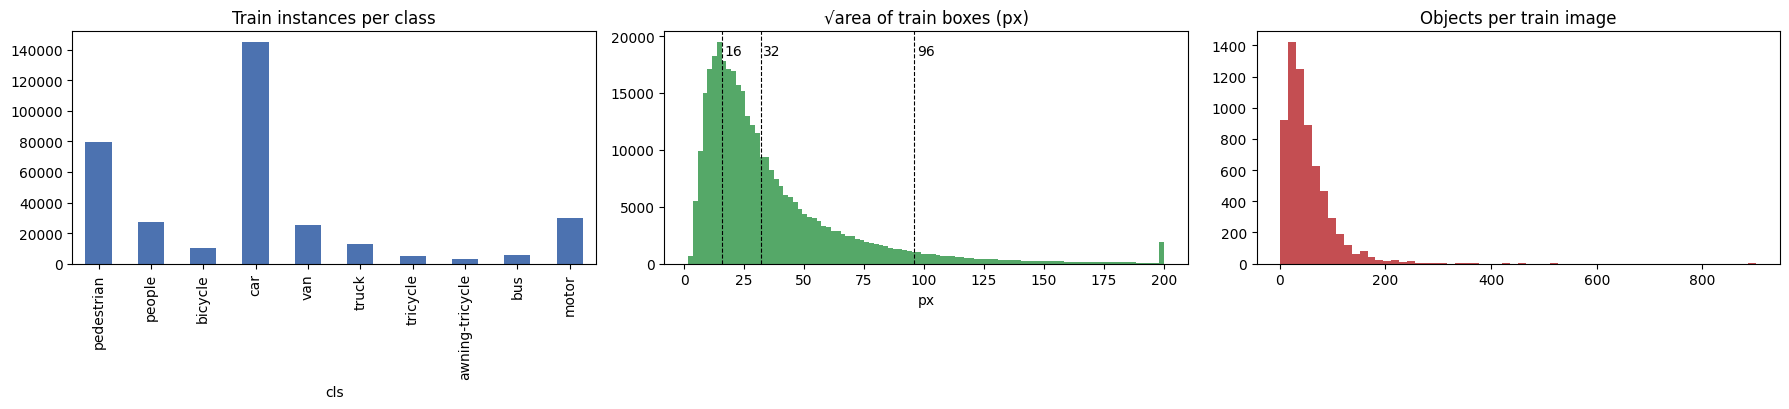

In [7]:
rows = [dict(split=s, cls=CLASSES[int(c)], w=w, h=h, img_w=r["w"], img_h=r["h"])
        for s, recs in RECS.items() for r in recs for c, x, y, w, h in r["boxes"]]
df = pd.DataFrame(rows); df["sqrt_area"] = np.sqrt(df.w * df.h)
df["size"] = pd.cut(df.sqrt_area, [0, 16, 32, 96, 1e9], labels=["tiny <16", "small 16-32", "medium 32-96", "large >96"])

size_tab = (pd.crosstab(df.split, df["size"], normalize="index") * 100).round(1)
print("Object-size distribution (% of boxes, COCO area convention):"); display(size_tab)
print("Image resolutions (train):"); display(pd.Series([f'{r["w"]}x{r["h"]}' for r in RECS["train"]]).value_counts().head(6))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
df[df.split == "train"].cls.value_counts().reindex(CLASSES).plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Train instances per class")
ax[1].hist(df[df.split == "train"].sqrt_area.clip(upper=200), bins=100, color="#55A868")
for v, l in [(16, "16"), (32, "32"), (96, "96")]: ax[1].axvline(v, ls="--", c="k", lw=0.8); ax[1].text(v + 1, ax[1].get_ylim()[1] * 0.9, l)
ax[1].set_title("√area of train boxes (px)"); ax[1].set_xlabel("px")
ax[2].hist([len(r["boxes"]) for r in RECS["train"]], bins=60, color="#C44E52"); ax[2].set_title("Objects per train image")
plt.tight_layout(); plt.savefig(OUT / "eda.png", dpi=130); plt.show()

## 3 · Build YOLO datasets
* **Full-image set** (baseline): original images with ignore regions greyed out.
* **Slice set** (SF): overlapping `TILE×TILE` crops at original resolution + the full images.
  A box is kept in a tile if ≥ `MIN_BOX_VISIBILITY` of its area is inside; most empty tiles are dropped (a few kept as negatives).

In [8]:
YOLO_ROOT = DATA / "yolo"

def masked_image(r):
    img = cv2.imread(str(r["file"]))
    if MASK_IGNORE:
        for x, y, w, h in r["ignore"].astype(int): img[max(y, 0):y + h, max(x, 0):x + w] = 114
    return img

def yolo_lines(boxes, W, H):
    return "".join(f"{int(c)} {(x + w / 2) / W:.6f} {(y + h / 2) / H:.6f} {w / W:.6f} {h / H:.6f}\n" for c, x, y, w, h in boxes)

def write_full(r, split):
    im_p = YOLO_ROOT / "images" / f"{split}_full" / f"{r['stem']}.jpg"
    lb_p = YOLO_ROOT / "labels" / f"{split}_full" / f"{r['stem']}.txt"
    if not im_p.exists():
        if MASK_IGNORE and len(r["ignore"]): cv2.imwrite(str(im_p), masked_image(r), [cv2.IMWRITE_JPEG_QUALITY, 95])
        else: os.symlink(r["file"], im_p)
    lb_p.write_text(yolo_lines(r["boxes"], r["w"], r["h"]))
    return 1

def write_tiles(r, split):
    img = masked_image(r); H, W = img.shape[:2]
    rng = random.Random(f"{SEED}-{r['stem']}"); n = 0
    b = r["boxes"]; x1, y1 = b[:, 1], b[:, 2]; x2, y2 = x1 + b[:, 3], y1 + b[:, 4]; area = b[:, 3] * b[:, 4]
    for tx1, ty1, tx2, ty2 in get_slice_bboxes(H, W, TILE, TILE, False, TILE_OVERLAP, TILE_OVERLAP):
        cx1, cy1 = np.clip(x1, tx1, tx2), np.clip(y1, ty1, ty2)
        cx2, cy2 = np.clip(x2, tx1, tx2), np.clip(y2, ty1, ty2)
        cw, ch = cx2 - cx1, cy2 - cy1
        keep = (cw >= MIN_BOX_SIDE) & (ch >= MIN_BOX_SIDE) & (cw * ch >= MIN_BOX_VISIBILITY * area)
        if not keep.any() and rng.random() > EMPTY_TILE_KEEP: continue
        tw, th = tx2 - tx1, ty2 - ty1
        tb = np.stack([b[keep, 0], cx1[keep] - tx1, cy1[keep] - ty1, cw[keep], ch[keep]], 1)
        name = f"{r['stem']}_{tx1}_{ty1}"
        cv2.imwrite(str(YOLO_ROOT / "images" / f"{split}_tiles" / f"{name}.jpg"), img[ty1:ty2, tx1:tx2], [cv2.IMWRITE_JPEG_QUALITY, 95])
        (YOLO_ROOT / "labels" / f"{split}_tiles" / f"{name}.txt").write_text(yolo_lines(tb, tw, th)); n += 1
    return n

def build(split, kind):
    for d in ("images", "labels"):
        p = YOLO_ROOT / d / f"{split}_{kind}"
        if p.exists() and d == "images" and FORCE_REBUILD: shutil.rmtree(p)
        p.mkdir(parents=True, exist_ok=True)
    done = YOLO_ROOT / f".{split}_{kind}.done"
    if done.exists(): return len(list((YOLO_ROOT / "images" / f"{split}_{kind}").glob("*.jpg")))
    fn = write_full if kind == "full" else write_tiles
    with ThreadPoolExecutor(WORKERS) as ex:     # cv2 releases the GIL → threads scale well
        n = sum(tqdm(ex.map(lambda r: fn(r, split), RECS[split]), total=len(RECS[split]), desc=f"{split}_{kind}"))
    done.touch(); return n

FORCE_REBUILD = False
counts = {f"{s}_{k}": build(s, k) for s in ("train", "val") for k in ("full", "tiles")}
print(counts)

def write_yaml(name, train, val):
    y = dict(path=str(YOLO_ROOT), train=train, val=val, names=dict(enumerate(CLASSES)))
    p = DATA / f"{name}.yaml"; yaml.safe_dump(y, open(p, "w"), sort_keys=False); return p

DATA_BASE = write_yaml("visdrone_full",  "images/train_full", "images/val_full")
DATA_SF   = write_yaml("visdrone_sahi_sf", ["images/train_tiles"] + (["images/train_full"] if SF_INCLUDE_FULL else []), "images/val_tiles")
print(open(DATA_SF).read())

train_full:   0%|          | 0/6471 [00:00<?, ?it/s]

train_tiles:   0%|          | 0/6471 [00:00<?, ?it/s]

val_full:   0%|          | 0/548 [00:00<?, ?it/s]

val_tiles:   0%|          | 0/548 [00:00<?, ?it/s]

{'train_full': 6471, 'train_tiles': 40410, 'val_full': 548, 'val_tiles': 2781}
path: /tmp/visdrone_sahi/yolo
train:
- images/train_tiles
- images/train_full
val: images/val_tiles
names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor



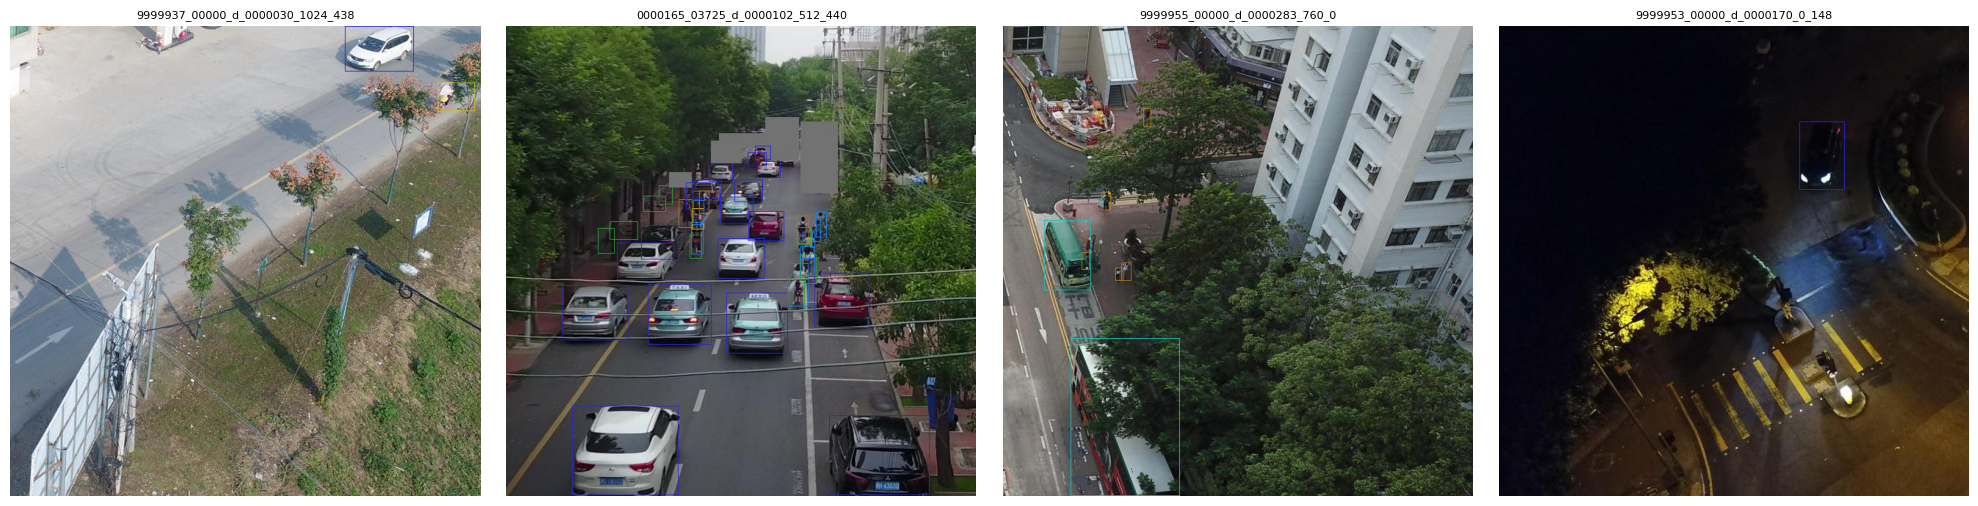

In [9]:
# Visual sanity check of generated tiles + labels
tiles = sorted((YOLO_ROOT / "images" / "train_tiles").glob("*.jpg"))
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, f in zip(axes, random.Random(SEED).sample(tiles, min(4, len(tiles)))):
    im = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    for ln in (YOLO_ROOT / "labels" / "train_tiles" / f"{f.stem}.txt").read_text().splitlines():
        c, xc, yc, bw, bh = map(float, ln.split())
        cv2.rectangle(im, (int((xc - bw / 2) * w), int((yc - bh / 2) * h)), (int((xc + bw / 2) * w), int((yc + bh / 2) * h)),
                      tuple(int(v) for v in plt.cm.tab10(int(c))[:3][::-1] * np.array(255)), 1)
    ax.imshow(im); ax.set_title(f.stem, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "tiles_sanity.png", dpi=110); plt.show()

## 4 · Training YOLO26
Both models start from the same COCO-pretrained YOLO26 checkpoint and use identical hyper-parameters; only the data differ.

| Run | Train data | Purpose |
|---|---|---|
| `base_fullimg` | 6 471 full images | conventional baseline |
| `sf_tiles` | tiles + full images | **slice-aided fine-tuning** (SAHI-SF) |

Augmentation: mosaic (closed for last 10 epochs), HSV, scale 0.5, h-flip. No rotation (aerial nadir-ish views keep "up" meaningful for vehicles/people).

In [10]:
HYP = dict(imgsz=IMGSZ, batch=BATCH, device=TRAIN_DEVICE, workers=WORKERS, seed=SEED, deterministic=False,
           optimizer="auto", cos_lr=True, close_mosaic=10, mosaic=1.0, mixup=0.0, copy_paste=0.0,
           degrees=0.0, scale=0.5, fliplr=0.5, amp=True, cache=False, plots=True,
           project=str(RUNS), exist_ok=True, verbose=False)

def train(name, data, epochs):
    run = RUNS / name; best, last, done = run / "weights" / "best.pt", run / "weights" / "last.pt", run / "DONE"
    if done.exists() and best.exists():
        print(f"[{name}] already trained → {best}"); return best
    t0 = time.time()
    if last.exists():
        print(f"[{name}] resuming from {last}"); YOLO(str(last)).train(resume=True)
    else:
        YOLO(MODEL_WEIGHTS).train(data=str(data), name=name, epochs=epochs, patience=PATIENCE, **HYP)
    done.write_text(f"{(time.time() - t0) / 3600:.2f} h"); print(f"[{name}] finished in {done.read_text()}")
    return best

W = {}
if TRAIN_BASELINE:
    W["base"] = train("base_fullimg", DATA_BASE, EPOCHS_BASE)
W["sf"] = train("sf_tiles", DATA_SF, EPOCHS_SF)
W

Ultralytics 8.4.165 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/tmp/visdrone_sahi/visdrone_full.yaml, degrees=0.0, deterministic=False, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, 

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/40      7.15G      2.127       1.69    0.00273        225        640: 100% ━━━━━━━━━━━━ 203/203 2.5it/s 1:21
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.1it/s 4.3s
                   all        548      38759      0.393      0.317      0.285      0.158

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/40      7.17G      2.087      1.603   0.002685        222        640: 100% ━━━━━━━━━━━━ 203/203 2.5it/s 1:20
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.9it/s 4.8s
                   all        548      38759      0.383      0.315       0.28      0.153

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/40      7.17G      2.094      1.582    0.00263        246        640: 100% ━━━━━━━━━━━━ 20

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/40      7.59G      1.817      1.472   0.003607         12        640: 100% ━━━━━━━━━━━━ 1466/1466 2.6it/s 9:20
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 2.5it/s 17.8s
                   all       2781      93701       0.56      0.458      0.478      0.287

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/40      6.15G      1.834      1.498   0.003738         22        640: 100% ━━━━━━━━━━━━ 1466/1466 2.7it/s 8:56
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 2.4it/s 18.0s
                   all       2781      93701      0.513      0.438      0.434      0.252

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/40      6.15G      1.871      1.518   0.003847         57        640: 100% ━━━━━

{'base': PosixPath('/kaggle/working/runs/base_fullimg/weights/best.pt'),
 'sf': PosixPath('/kaggle/working/runs/sf_tiles/weights/best.pt')}

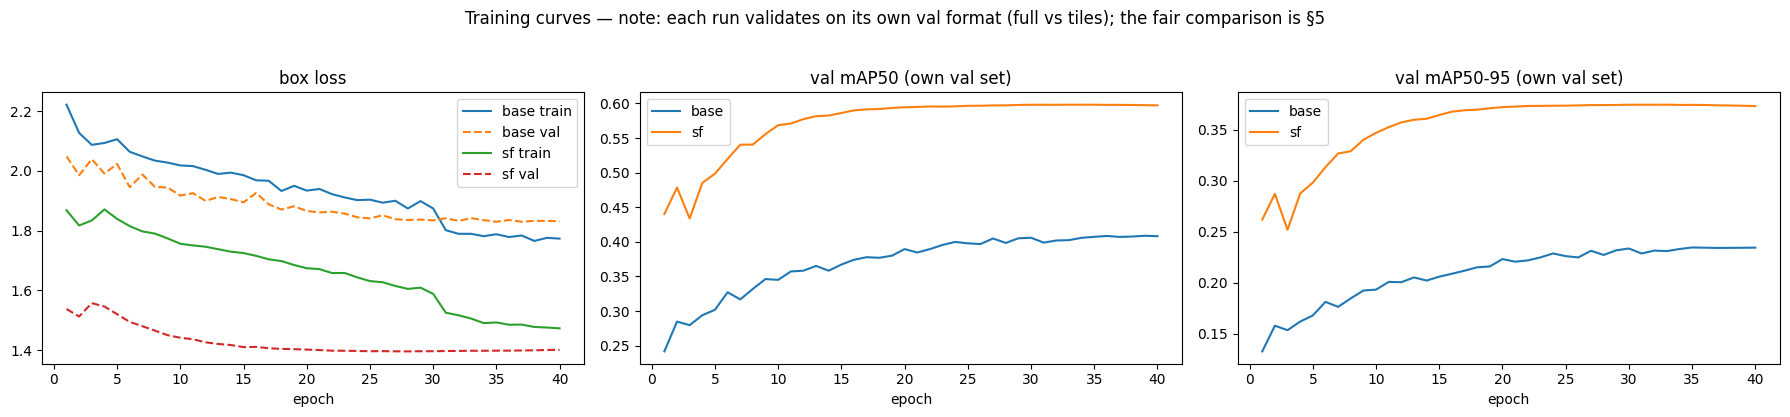

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for key, run in [("base", "base_fullimg"), ("sf", "sf_tiles")]:
    f = RUNS / run / "results.csv"
    if not f.exists(): continue
    r = pd.read_csv(f); r.columns = [c.strip() for c in r.columns]
    ax[0].plot(r.epoch, r["train/box_loss"], label=f"{key} train"); ax[0].plot(r.epoch, r["val/box_loss"], "--", label=f"{key} val")
    ax[1].plot(r.epoch, r["metrics/mAP50(B)"], label=key); ax[2].plot(r.epoch, r["metrics/mAP50-95(B)"], label=key)
for a, t in zip(ax, ["box loss", "val mAP50 (own val set)", "val mAP50-95 (own val set)"]): a.set_title(t); a.legend(); a.set_xlabel("epoch")
plt.suptitle("Training curves — note: each run validates on its own val format (full vs tiles); the fair comparison is §5", y=1.03)
plt.tight_layout(); plt.savefig(OUT / "training_curves.png", dpi=120, bbox_inches="tight"); plt.show()

## 5 · Unified evaluation harness
Every method outputs detections in **original-image coordinates** and is scored by the same COCO evaluator
(ignore regions as crowd, `maxDets=500`, extra **tiny** size bucket).

In [12]:
AREA_RNG = {"all": [0, 1e10], "tiny": [0, 16 ** 2], "small": [0, 32 ** 2], "medium": [32 ** 2, 96 ** 2], "large": [96 ** 2, 1e10]}

def coco_eval(split, dets):
    gt = COCO_GT[split]
    if not dets: return {k: 0.0 for k in ["AP", "AP50", "AP75", "AP_tiny", "AP_s", "AP_m", "AP_l", "AR500"]}, np.zeros(len(CLASSES))
    with contextlib.redirect_stdout(io.StringIO()):
        dt = gt.loadRes(dets); E = COCOeval(gt, dt, "bbox")
        E.params.maxDets = [1, 100, MAX_DETS]
        E.params.areaRng, E.params.areaRngLbl = list(AREA_RNG.values()), list(AREA_RNG.keys())
        E.evaluate(); E.accumulate()
    P, R = E.eval["precision"], E.eval["recall"]       # P: [T,R,K,A,M]  R: [T,K,A,M]
    def ap(area="all", t=None, k=slice(None)):
        a = E.params.areaRngLbl.index(area); p = P[:, :, k, a, -1] if t is None else P[[t], :, k, a, -1]
        p = p[p > -1]; return float(p.mean()) if p.size else float("nan")
    r = R[:, :, 0, -1]; r = r[r > -1]
    m = dict(AP=ap(), AP50=ap(t=0), AP75=ap(t=5), AP_tiny=ap("tiny"), AP_s=ap("small"), AP_m=ap("medium"),
             AP_l=ap("large"), AR500=float(r.mean()) if r.size else float("nan"))
    per_cls = np.array([ap(k=k) for k in range(len(CLASSES))])
    return m, per_cls

_YOLO_CACHE = {}
def predict_full(weights, split, imgsz):
    model = _YOLO_CACHE.setdefault(str(weights), YOLO(str(weights)))
    recs = RECS[split]; dets, times = [], []
    model.predict(str(recs[0]["file"]), imgsz=imgsz, device=DEVICE, verbose=False)          # warm-up
    for r in tqdm(recs, desc=f"FI@{imgsz}", leave=False):
        if N_GPU: torch.cuda.synchronize()
        t0 = time.perf_counter()
        res = model.predict(str(r["file"]), imgsz=imgsz, conf=EVAL_CONF, max_det=MAX_DETS, device=DEVICE, verbose=False)[0]
        if N_GPU: torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
        b = res.boxes
        for (x1, y1, x2, y2), s, c in zip(b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy()):
            dets.append(dict(image_id=r["id"], category_id=int(c) + 1, bbox=[float(x1), float(y1), float(x2 - x1), float(y2 - y1)], score=float(s)))
    return dets, 1000 * float(np.mean(times))

_SAHI_CACHE = {}
def sahi_model(weights, conf=EVAL_CONF, image_size=IMGSZ):
    key = (str(weights), conf, image_size)
    if key not in _SAHI_CACHE:
        _SAHI_CACHE[key] = AutoDetectionModel.from_pretrained(model_type="ultralytics", model_path=str(weights),
                                                              confidence_threshold=conf, device=SAHI_DEVICE, image_size=image_size)
    return _SAHI_CACHE[key]

def run_sahi(model, image, slice_=640, overlap=0.2, fi=True, pp="GREEDYNMM", metric="IOS", thr=0.5):
    return get_sliced_prediction(image, model, slice_height=slice_, slice_width=slice_, overlap_height_ratio=overlap,
                                 overlap_width_ratio=overlap, perform_standard_pred=fi, postprocess_type=pp,
                                 postprocess_match_metric=metric, postprocess_match_threshold=thr,
                                 postprocess_class_agnostic=False, verbose=0, batch_size=SAHI_BATCH,
                                 force_postprocess_type=True)   # SAHI otherwise silently swaps to NMS when conf<0.1 → would invalidate the merge ablation

def predict_sahi(weights, split, **cfg):
    model = sahi_model(weights); recs = RECS[split]; dets, times = [], []
    run_sahi(model, str(recs[0]["file"]), **cfg)                                             # warm-up
    for r in tqdm(recs, desc="SAHI", leave=False):
        if N_GPU: torch.cuda.synchronize()
        t0 = time.perf_counter(); res = run_sahi(model, str(r["file"]), **cfg)
        if N_GPU: torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
        preds = sorted(res.object_prediction_list, key=lambda p: -p.score.value)[:MAX_DETS]
        for p in preds:
            bb = p.bbox
            dets.append(dict(image_id=r["id"], category_id=int(p.category.id) + 1,
                             bbox=[float(bb.minx), float(bb.miny), float(bb.maxx - bb.minx), float(bb.maxy - bb.miny)], score=float(p.score.value)))
    return dets, 1000 * float(np.mean(times))

PRED_CACHE = {}   # compact numpy arrays: [image_id, category_id, x, y, w, h, score]
def evaluate(cfg, split):
    cfg = dict(cfg); name, kind, w = cfg.pop("name"), cfg.pop("kind"), cfg.pop("w")
    if w not in W: return None
    dets, ms = predict_full(W[w], split, cfg["imgsz"]) if kind == "full" else predict_sahi(W[w], split, **cfg)
    PRED_CACHE[(name, split)] = np.array([[d["image_id"], d["category_id"], *d["bbox"], d["score"]] for d in dets], np.float32).reshape(-1, 7)
    m, per_cls = coco_eval(split, dets)
    print(f"{name:<48s} AP={m['AP']:.4f} AP50={m['AP50']:.4f} AP_tiny={m['AP_tiny']:.4f}  {ms:.1f} ms/img")
    return dict(method=name, **m, ms_per_img=ms, dets_per_img=len(dets) / len(RECS[split])), per_cls

## 6 · Ablation study on **val**
Rows follow the SAHI paper (FI / SF / SAHI / FI+SAHI / SF+SAHI+FI / overlap) and extend it with
slice-size (zoom), merge algorithm and match-metric studies. **The best row is selected here, on val only.**

In [13]:
S = dict(slice_=640, overlap=0.2, fi=True, pp="GREEDYNMM", metric="IOS", thr=0.5)   # SAHI default config
def sahi_cfg(name, w="sf", **kw): return dict(name=name, kind="sahi", w=w, **{**S, **kw})

ABLATION = [
    # ---- baselines: conventional training -----------------------------------
    dict(name="BASE · FI@640",                    kind="full", w="base", imgsz=640),
    dict(name="BASE · FI@1280",                   kind="full", w="base", imgsz=1280),
    sahi_cfg("BASE · SAHI (no FI)",               w="base", fi=False),
    sahi_cfg("BASE · SAHI + FI",                  w="base"),
    # ---- slice-aided fine-tuning -------------------------------------------
    dict(name="SF · FI@640",                      kind="full", w="sf", imgsz=640),
    dict(name="SF · FI@1280",                     kind="full", w="sf", imgsz=1280),
    sahi_cfg("SF · SAHI (no FI)",                 fi=False),
    sahi_cfg("SF · SAHI + FI  [default]"),
    # ---- overlap -------------------------------------------------------------
    sahi_cfg("SF · SAHI + FI · overlap 0.10",     overlap=0.10),
    sahi_cfg("SF · SAHI + FI · overlap 0.30",     overlap=0.30),
    # ---- slice size = zoom factor (network input fixed at 640) ---------------
    sahi_cfg("SF · SAHI + FI · slice 512 (1.25×)", slice_=512),
    sahi_cfg("SF · SAHI + FI · slice 448 (1.43×)", slice_=448),
    sahi_cfg("SF · SAHI + FI · slice 800 (0.8×)",  slice_=800),
    # ---- merging -------------------------------------------------------------
    sahi_cfg("SF · SAHI + FI · NMS-IOU 0.5",      pp="NMS", metric="IOU"),
    sahi_cfg("SF · SAHI + FI · NMM-IOS 0.5",      pp="NMM"),
    sahi_cfg("SF · SAHI + FI · GREEDYNMM-IOU 0.5", metric="IOU"),
    sahi_cfg("SF · SAHI + FI · GREEDYNMM-IOS 0.7", thr=0.7),
]
if FAST_DEV_RUN: ABLATION = ABLATION[:2] + ABLATION[4:8] + ABLATION[10:11]

val_rows, val_cls = [], {}
for cfg in ABLATION:
    out = evaluate(cfg, "val")
    if out: val_rows.append(out[0]); val_cls[cfg["name"]] = out[1]
VAL = pd.DataFrame(val_rows).set_index("method")
VAL.to_csv(OUT / "ablation_val.csv")
VAL.style.format("{:.4f}", subset=[c for c in VAL.columns if c.startswith("A")]).format("{:.1f}", subset=["ms_per_img", "dets_per_img"]) \
   .background_gradient(cmap="Greens", subset=["AP", "AP50", "AP_tiny", "AP_s"])

FI@640:   0%|          | 0/548 [00:00<?, ?it/s]

BASE · FI@640                                    AP=0.2163 AP50=0.3663 AP_tiny=0.0610  25.3 ms/img


FI@1280:   0%|          | 0/548 [00:00<?, ?it/s]

BASE · FI@1280                                   AP=0.2794 AP50=0.4682 AP_tiny=0.1263  31.0 ms/img


SAHI:   0%|          | 0/548 [00:00<?, ?it/s]

BASE · SAHI (no FI)                              AP=0.2017 AP50=0.3738 AP_tiny=0.0916  128.6 ms/img


... (25 outputs left out)

SF · SAHI + FI · GREEDYNMM-IOU 0.5               AP=0.2819 AP50=0.5019 AP_tiny=0.1152  147.2 ms/img


SAHI:   0%|          | 0/548 [00:00<?, ?it/s]

SF · SAHI + FI · GREEDYNMM-IOS 0.7               AP=0.2703 AP50=0.4872 AP_tiny=0.1098  149.5 ms/img


,AP,AP50,AP75,AP_tiny,AP_s,AP_m,AP_l,AR500,ms_per_img,dets_per_img
method,,,,,,,,,,
BASE · FI@640,0.2163,0.3663,0.2142,0.0610,0.1240,0.3213,0.5110,0.3079,25.3,241.8
BASE · FI@1280,0.2794,0.4682,0.2812,0.1263,0.2023,0.3733,0.4152,0.4086,31.0,295.0
BASE · SAHI (no FI),0.2017,0.3738,0.1885,0.0916,0.1450,0.2616,0.3077,0.3212,128.6,222.7
BASE · SAHI + FI,0.1867,0.3558,0.1723,0.0745,0.1271,0.2468,0.3915,0.3121,165.8,261.7
SF · FI@640,0.2390,0.3968,0.2385,0.0687,0.1399,0.3610,0.6118,0.3219,23.4,220.8
SF · FI@1280,0.3463,0.5506,0.3579,0.1554,0.2563,0.4684,0.5605,0.4540,30.2,238.3
SF · SAHI (no FI),0.2752,0.4802,0.2667,0.1191,0.1997,0.3788,0.5258,0.3776,118.3,168.4
SF · SAHI + FI [default],0.2436,0.4448,0.2272,0.0957,0.1701,0.3382,0.5339,0.3498,154.9,205.8
SF · SAHI + FI · overlap 0.10,0.2449,0.4476,0.2306,0.0971,0.1716,0.3406,0.5283,0.3505,152.6,205.1


Best on val : SF · FI@1280
  cfg = {'name': 'SF · FI@1280', 'kind': 'full', 'w': 'sf', 'imgsz': 1280}
Reference   : BASE · FI@640
Δ AP  = +13.00 pts   Δ AP_tiny = +9.44 pts


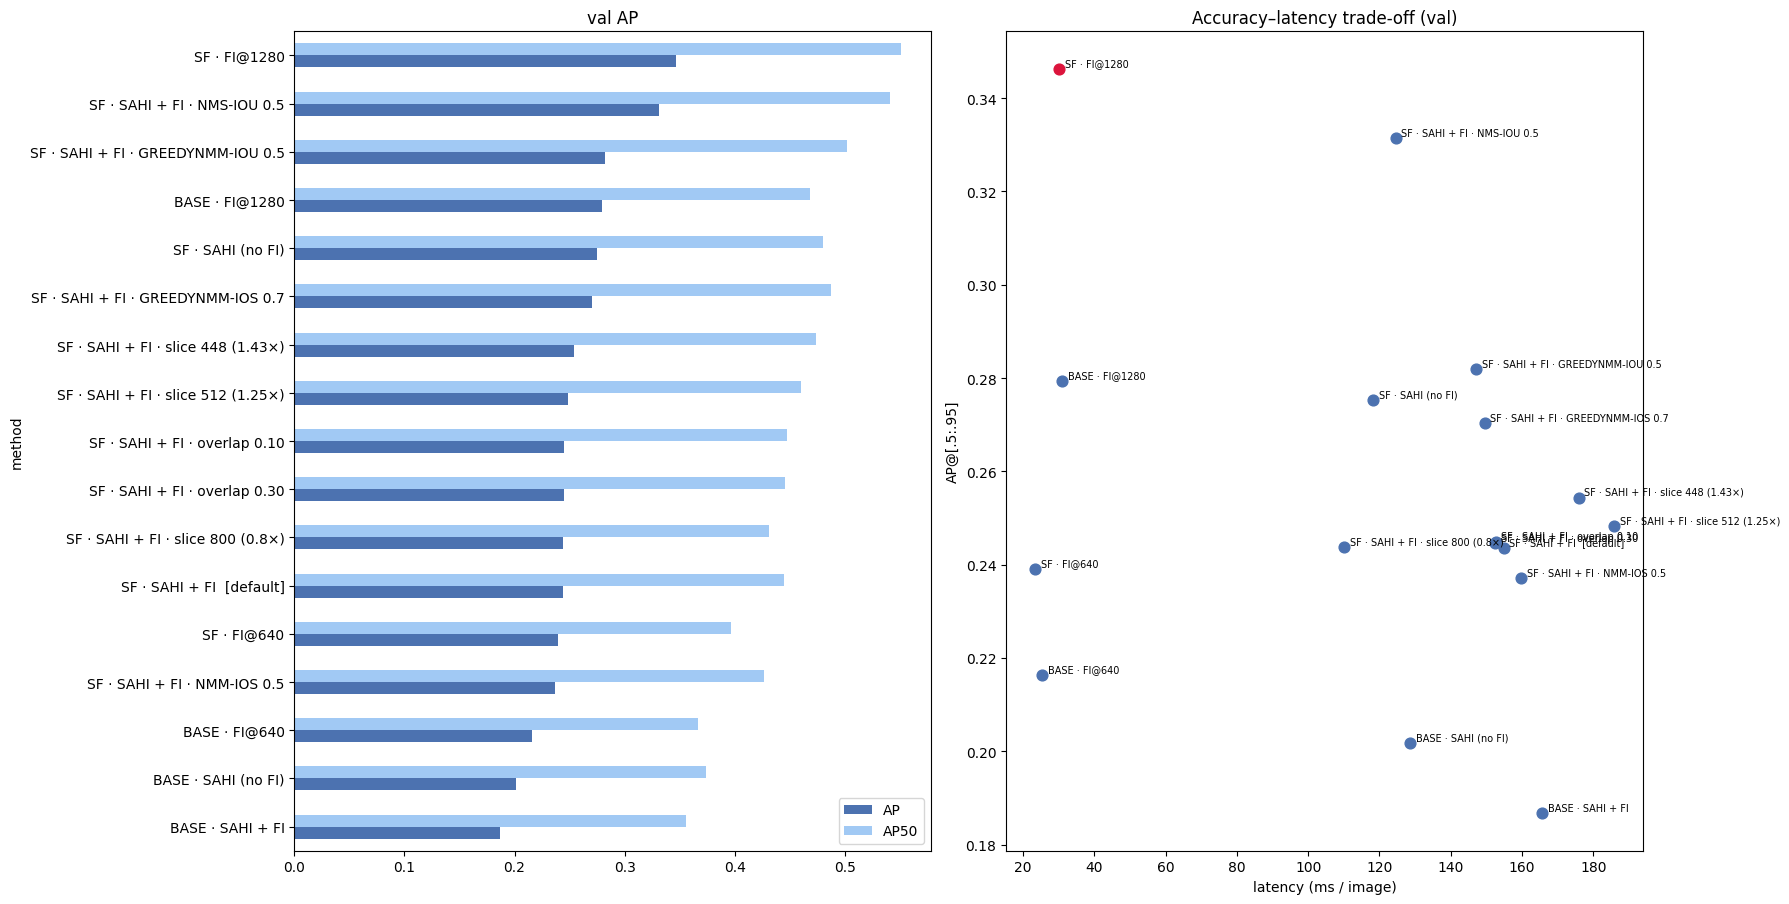

In [14]:
# Select the best configuration on val: highest AP@[.5:.95]; ties (<0.1 AP pt) broken by latency
v = VAL.sort_values("AP", ascending=False)
cands = v[v.AP >= v.AP.iloc[0] - 0.001]
BEST_NAME = cands.ms_per_img.idxmin()
BEST_CFG  = next(c for c in ABLATION if c["name"] == BEST_NAME)
REF_NAME  = "BASE · FI@640" if "BASE · FI@640" in VAL.index else "SF · FI@640"
print(f"Best on val : {BEST_NAME}\n  cfg = {BEST_CFG}")
print(f"Reference   : {REF_NAME}")
print(f"Δ AP  = {100 * (VAL.loc[BEST_NAME, 'AP'] - VAL.loc[REF_NAME, 'AP']):+.2f} pts   "
      f"Δ AP_tiny = {100 * (VAL.loc[BEST_NAME, 'AP_tiny'] - VAL.loc[REF_NAME, 'AP_tiny']):+.2f} pts")

fig, ax = plt.subplots(1, 2, figsize=(18, 0.45 * len(VAL) + 1.5))
v[["AP", "AP50"]].iloc[::-1].plot.barh(ax=ax[0], color=["#4C72B0", "#A1C9F4"]); ax[0].set_title("val AP")
for i, (n, row) in enumerate(v.iloc[::-1].iterrows()):
    ax[1].scatter(row.ms_per_img, row.AP, s=60, c="crimson" if n == BEST_NAME else "#4C72B0")
    ax[1].annotate(n, (row.ms_per_img, row.AP), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax[1].set_xlabel("latency (ms / image)"); ax[1].set_ylabel("AP@[.5:.95]"); ax[1].set_title("Accuracy–latency trade-off (val)")
plt.tight_layout(); plt.savefig(OUT / "ablation_val.png", dpi=130); plt.show()

## 7 · Final report on held-out **test-dev**
Only the reference baselines and the val-selected configuration are run on test-dev — once.

In [15]:
FINAL = []
for n in dict.fromkeys(["BASE · FI@640", "BASE · FI@1280", "SF · FI@640", "SF · SAHI + FI  [default]", BEST_NAME]):
    c = next((c for c in ABLATION if c["name"] == n), None)
    if c is not None and c["w"] in W: FINAL.append(c)

test_rows, test_cls = [], {}
for cfg in FINAL:
    out = evaluate(cfg, "test")
    if out: test_rows.append(out[0]); test_cls[cfg["name"]] = out[1]
TEST = pd.DataFrame(test_rows).set_index("method")
TEST.to_csv(OUT / "results_testdev.csv")
TEST.style.format("{:.4f}", subset=[c for c in TEST.columns if c.startswith("A")]).format("{:.1f}", subset=["ms_per_img", "dets_per_img"]) \
    .highlight_max(color="#c6efce", subset=["AP", "AP50", "AP75", "AP_tiny", "AP_s", "AP_m", "AR500"])

FI@640:   0%|          | 0/1610 [00:00<?, ?it/s]

BASE · FI@640                                    AP=0.1774 AP50=0.3080 AP_tiny=0.0438  39.9 ms/img


FI@1280:   0%|          | 0/1610 [00:00<?, ?it/s]

BASE · FI@1280                                   AP=0.2243 AP50=0.3875 AP_tiny=0.0836  33.6 ms/img


FI@640:   0%|          | 0/1610 [00:00<?, ?it/s]

SF · FI@640                                      AP=0.1918 AP50=0.3273 AP_tiny=0.0431  23.3 ms/img


SAHI:   0%|          | 0/1610 [00:00<?, ?it/s]

SF · SAHI + FI  [default]                        AP=0.1905 AP50=0.3563 AP_tiny=0.0638  144.7 ms/img


FI@1280:   0%|          | 0/1610 [00:00<?, ?it/s]

SF · FI@1280                                     AP=0.2684 AP50=0.4477 AP_tiny=0.0991  33.8 ms/img


,AP,AP50,AP75,AP_tiny,AP_s,AP_m,AP_l,AR500,ms_per_img,dets_per_img
method,,,,,,,,,,
BASE · FI@640,0.1774,0.3080,0.1789,0.0438,0.0838,0.2698,0.4173,0.2752,39.9,165.8
BASE · FI@1280,0.2243,0.3875,0.2243,0.0836,0.1426,0.3123,0.3430,0.3517,33.6,186.8
SF · FI@640,0.1918,0.3273,0.1956,0.0431,0.0887,0.2973,0.5000,0.2799,23.3,142.2
SF · SAHI + FI [default],0.1905,0.3563,0.1820,0.0638,0.1084,0.2811,0.3776,0.2950,144.7,137.6
SF · FI@1280,0.2684,0.4477,0.2727,0.0991,0.1644,0.3830,0.5089,0.3797,33.8,132.1


,pedestrian,people,bicycle,car,van,truck,tricycle,awning-tricycle,bus,motor
BASE · FI@640,12.320000,4.670000,3.700000,44.410000,18.830000,24.690000,10.080000,9.550000,36.640000,12.550000
BASE · FI@1280,19.100000,7.710000,6.760000,51.700000,25.850000,29.010000,13.120000,11.340000,40.900000,18.780000
SF · FI@640,12.780000,6.400000,4.500000,45.710000,19.950000,27.020000,10.940000,12.190000,38.350000,13.960000
SF · SAHI + FI [default],9.460000,4.940000,6.910000,40.290000,27.580000,21.550000,14.890000,15.520000,38.310000,11.050000
SF · FI@1280,20.670000,11.900000,11.040000,53.360000,29.010000,36.880000,19.360000,16.790000,46.600000,22.760000


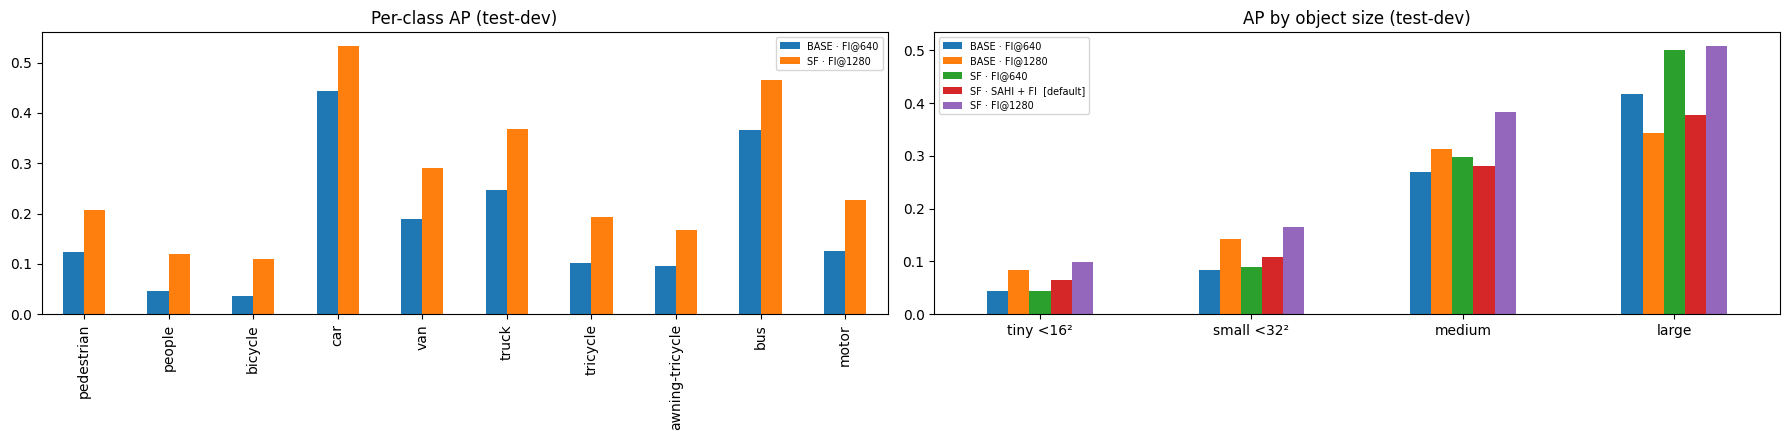

In [16]:
PC = pd.DataFrame(test_cls, index=CLASSES).T
display((PC * 100).round(2).style.background_gradient(cmap="Blues", axis=0).set_caption("test-dev per-class AP@[.5:.95] (%)"))

fig, ax = plt.subplots(1, 2, figsize=(18, 4.5))
PC.T[[c for c in dict.fromkeys([REF_NAME, BEST_NAME]) if c in PC.index]].plot.bar(ax=ax[0]); ax[0].set_title("Per-class AP (test-dev)")
TEST[["AP_tiny", "AP_s", "AP_m", "AP_l"]].T.plot.bar(ax=ax[1]); ax[1].set_title("AP by object size (test-dev)")
ax[1].set_xticklabels(["tiny <16²", "small <32²", "medium", "large"], rotation=0)
for a in ax: a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "testdev_breakdown.png", dpi=130); plt.show()

## 8 · Qualitative comparison (val)

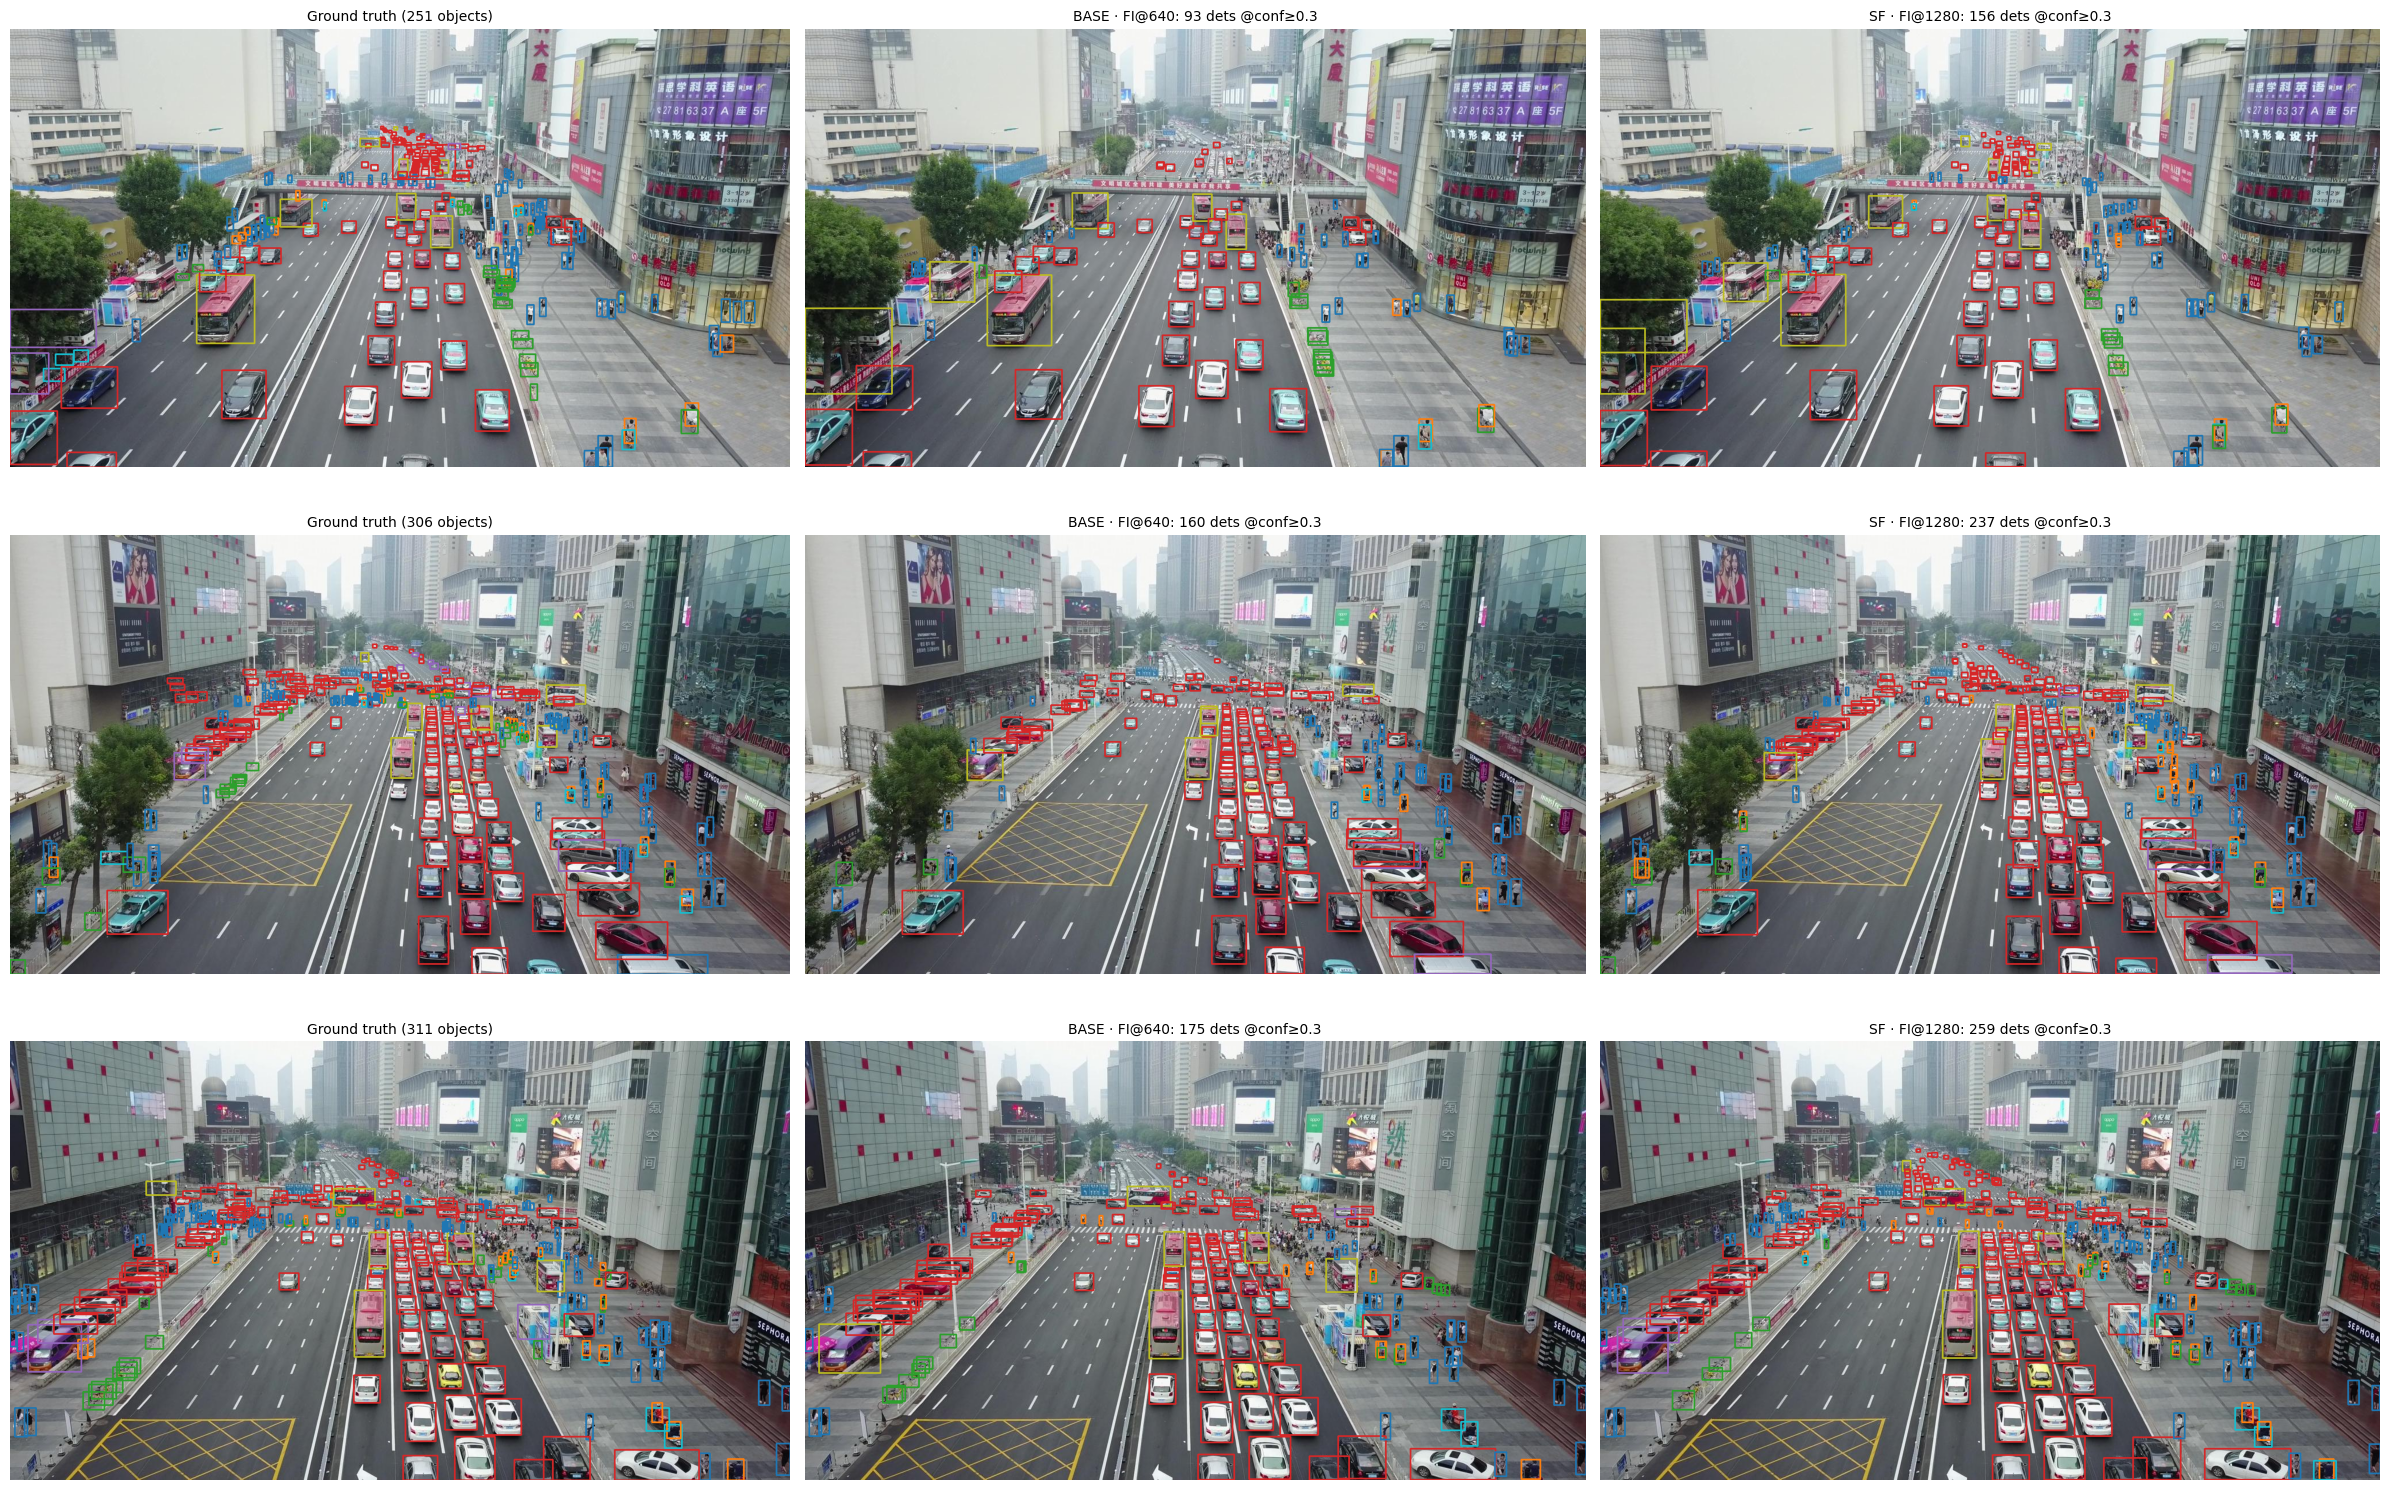

In [17]:
def draw(ax, r, boxes, title):
    im = cv2.cvtColor(cv2.imread(str(r["file"])), cv2.COLOR_BGR2RGB)
    for c, x, y, w, h in boxes:
        col = tuple(int(255 * v) for v in plt.cm.tab10(int(c) % 10)[:3])
        cv2.rectangle(im, (int(x), int(y)), (int(x + w), int(y + h)), col, 2)
    ax.imshow(im); ax.set_title(title, fontsize=10); ax.axis("off")

def dets_for(name, r, split="val"):
    a = PRED_CACHE[(name, split)]; a = a[(a[:, 0] == r["id"]) & (a[:, 6] >= VIS_CONF)]
    return [(c - 1, x, y, w, h) for _, c, x, y, w, h, _ in a]

def n_tiny(r): return int(((r["boxes"][:, 3] * r["boxes"][:, 4]) < 16 ** 2).sum()) if len(r["boxes"]) else 0
show = sorted(RECS["val"], key=n_tiny, reverse=True)[:3]
fig, axes = plt.subplots(len(show), 3, figsize=(24, 5.2 * len(show)))
axes = np.atleast_2d(axes)
for row, r in zip(axes, show):
    draw(row[0], r, r["boxes"], f"Ground truth ({len(r['boxes'])} objects)")
    d0, d1 = dets_for(REF_NAME, r), dets_for(BEST_NAME, r)
    draw(row[1], r, d0, f"{REF_NAME}: {len(d0)} dets @conf≥{VIS_CONF}")
    draw(row[2], r, d1, f"{BEST_NAME}: {len(d1)} dets @conf≥{VIS_CONF}")
plt.tight_layout(); plt.savefig(OUT / "qualitative.png", dpi=110); plt.show()

## 9 · Export the deployable detector

66 objects in 0000006_00159_d_0000001.jpg


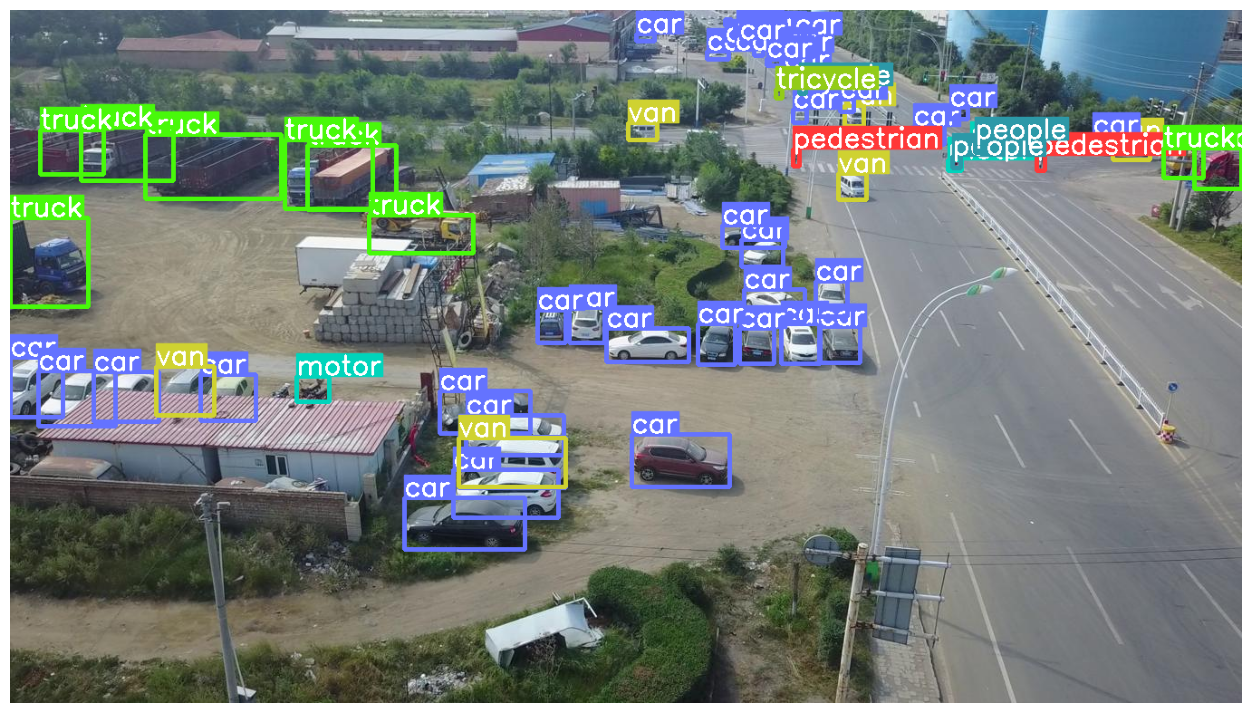

In [18]:
best_w = W[BEST_CFG["w"]]
shutil.copy(best_w, OUT / "yolo26_visdrone_best.pt")
DEPLOY = dict(weights="yolo26_visdrone_best.pt", method=BEST_NAME, imgsz=BEST_CFG.get("imgsz", IMGSZ), kind=BEST_CFG["kind"],
              sahi={k: BEST_CFG[k] for k in S if k in BEST_CFG}, classes=CLASSES,
              val=VAL.loc[BEST_NAME].to_dict(), testdev=TEST.loc[BEST_NAME].to_dict() if BEST_NAME in TEST.index else None, env=ENV)
json.dump(DEPLOY, open(OUT / "inference_config.json", "w"), indent=2, default=float)

def detect(image, conf=VIS_CONF):
    # Run the val-selected pipeline on any image (path / np.ndarray RGB / PIL). Returns a sahi PredictionResult.
    if DEPLOY["kind"] == "full":
        from sahi.predict import get_prediction
        return get_prediction(image, sahi_model(best_w, conf, DEPLOY["imgsz"]))
    return run_sahi(sahi_model(best_w, conf), image, **DEPLOY["sahi"])

demo = RECS["test"][0]["file"]
res = detect(str(demo)); res.export_visuals(export_dir=str(OUT), file_name="demo_prediction", hide_conf=True)
print(f"{len(res.object_prediction_list)} objects in {demo.name}")
plt.figure(figsize=(16, 9)); plt.imshow(Image.open(OUT / "demo_prediction.png")); plt.axis("off"); plt.show()

In [19]:
# Summary for the write-up
summary = TEST[["AP", "AP50", "AP75", "AP_tiny", "AP_s", "AP_m", "AP_l", "AR500", "ms_per_img"]].copy()
summary[summary.columns[:-1]] *= 100
print(summary.round(2).to_string())
print(f"\nSelected on val: {BEST_NAME}")
print("Artifacts:", sorted(p.name for p in OUT.iterdir()))

                              AP   AP50   AP75  AP_tiny   AP_s   AP_m   AP_l  AR500  ms_per_img
method                                                                                         
BASE · FI@640              17.74  30.80  17.89     4.38   8.38  26.98  41.73  27.52       39.90
BASE · FI@1280             22.43  38.75  22.43     8.36  14.26  31.23  34.30  35.17       33.58
SF · FI@640                19.18  32.73  19.56     4.31   8.87  29.73  50.00  27.99       23.27
SF · SAHI + FI  [default]  19.05  35.63  18.20     6.38  10.84  28.11  37.76  29.50      144.65
SF · FI@1280               26.84  44.77  27.27     9.91  16.44  38.30  50.89  37.97       33.77

Selected on val: SF · FI@1280
Artifacts: ['ablation_val.csv', 'ablation_val.png', 'demo_prediction.png', 'eda.png', 'environment.json', 'inference_config.json', 'qualitative.png', 'results_testdev.csv', 'testdev_breakdown.png', 'tiles_sanity.png', 'training_curves.png', 'yolo26_visdrone_best.pt']


## 10 · Discussion, limitations & next steps

**Reading the tables.** SAHI's gains concentrate in the *tiny/small* buckets (objects that shrink below the stride-8 receptive field when a
1360×765 frame is squeezed into 640 px). The FI pass matters for *large* objects that slices cut in half. SF lets a single model perform well at
both scales; without it, SAHI feeds the baseline objects at a scale it rarely saw during training.

**Caveats (state these in any paper/report):**
* SAHI is called with `force_postprocess_type=True`: by default SAHI silently replaces GREEDY-NMM/IoS with NMS/IoU whenever the model's score floor is < 0.1, which would make the merge ablation meaningless. If NMS wins the merge study here, that is the reason (low-score boxes get fused into oversized boxes by NMM).
* `EVAL_CONF=0.01` is used for every method (instead of 0.001) to keep sliced merging tractable; AP is slightly under-estimated for all rows equally.
* Numbers are COCO-style AP with VisDrone ignore regions — comparable to, but not bit-identical with, the official MATLAB VisDrone toolkit.
* Latency is end-to-end Python wall-clock on the Kaggle GPU (FP32, includes JPEG decode); TensorRT would shrink both FI and SAHI.
* One seed. For publication, repeat training with ≥3 seeds and report mean ± std.

**Ways to push accuracy further:** `PROFILE="max_accuracy"` (YOLO26l, 80 epochs) · train at `IMGSZ=800` tiles · multi-scale slicing ensemble (512+640+FI)
· weighted-box-fusion merge · test-time flip augmentation · pseudo-label test-challenge.

### References
1. F. C. Akyon, S. O. Altinuc, A. Temizel. *Slicing Aided Hyper Inference and Fine-tuning for Small Object Detection.* ICIP 2022. arXiv:2202.06934
2. P. Zhu et al. *Detection and Tracking Meet Drones Challenge.* IEEE TPAMI 2021 (VisDrone).
3. Ultralytics. *YOLO26* documentation, 2026 — https://docs.ultralytics.com/models/yolo26
4. T.-Y. Lin et al. *Microsoft COCO: Common Objects in Context.* ECCV 2014 (evaluation protocol).